# TC5061 — Modelo baseline de calidad del vino tinto

**Autor:** Carlos Ojeda, A01741085  
**Dataset:** Wine Quality (vino tinto), UCI Machine Learning Repository  
**Tipo de problema:** Regresión supervisada  
**Variable objetivo:** `quality`

## Objetivo
Construir un flujo reproducible de Machine Learning para estimar la calidad sensorial de un vino tinto a partir de sus propiedades fisicoquímicas. El notebook incluye carga y descripción de datos, análisis exploratorio, limpieza documentada, entrenamiento y evaluación de un modelo baseline y registro del experimento con MLflow Tracking.

> El modelo tiene fines académicos. La variable objetivo corresponde a evaluaciones sensoriales y no representa por sí sola una certificación comercial de calidad.

## 1. Fuente y contexto del dataset

El conjunto **Wine Quality** fue publicado por Cortez et al. (2009) y está disponible en el [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/186/wine+quality). Cada fila representa un análisis de vino tinto *Vinho Verde* de Portugal. Las entradas son mediciones fisicoquímicas y `quality` es una calificación sensorial entera.

La pregunta de modelado es:

> **¿Qué tan bien puede una regresión lineal estimar la calidad sensorial del vino a partir de sus propiedades fisicoquímicas?**

La calidad es ordinal y discreta, pero se aborda como regresión para obtener una estimación numérica y medir la magnitud del error. Esta decisión se documenta como una simplificación del baseline.

In [1]:
# Importaciones y configuración reproducible
from pathlib import Path
import json
import platform
import sys
import warnings

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Image, Markdown, display
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
TEST_SIZE = 0.20
PROJECT_ROOT = Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "winequality-red.csv"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

print(f"Python: {sys.version.split()[0]}")
print(f"pandas: {pd.__version__} | scikit-learn: {sklearn.__version__} | MLflow: {mlflow.__version__}")
print(f"Plataforma: {platform.platform()}")

2026/10/04 17:13:38 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/carlos/Documents/09_Proy_Neni/Arquitectura/NeniBot/.venv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Python: 3.13.5
pandas: 3.0.6 | scikit-learn: 1.9.1 | MLflow: 3.16.1
Plataforma: macOS-27.0-arm64-arm-64bit-Mach-O


## 2. Carga y descripción

El archivo utiliza punto y coma como separador. Se comprueba explícitamente su existencia para producir un error claro si el notebook se ejecuta fuera de la estructura entregada.

In [2]:
# Descarga reproducible si el CSV no acompaña al notebook.
# Si ya existe localmente, no se realiza ninguna solicitud de red.
if not DATA_PATH.exists():
    from io import BytesIO
    from urllib.request import urlopen
    from zipfile import ZipFile

    dataset_url = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    with urlopen(dataset_url) as response, ZipFile(BytesIO(response.read())) as archive:
        DATA_PATH.write_bytes(archive.read("winequality-red.csv"))

raw_df = pd.read_csv(DATA_PATH, sep=";")
df = raw_df.copy()

print(f"Registros: {df.shape[0]:,}")
print(f"Variables: {df.shape[1]}")
display(df.head())
df.info()

Registros: 1,599
Variables: 12


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


### Diccionario de variables

- `fixed acidity`: ácidos no volátiles, principalmente tartárico.
- `volatile acidity`: ácidos volátiles; valores altos pueden producir sabor avinagrado.
- `citric acid`: ácido cítrico.
- `residual sugar`: azúcar restante después de la fermentación.
- `chlorides`: concentración de sales.
- `free sulfur dioxide`: dióxido de azufre libre.
- `total sulfur dioxide`: dióxido de azufre total.
- `density`: densidad del vino.
- `pH`: nivel de acidez o alcalinidad.
- `sulphates`: sulfatos, relacionados con la conservación.
- `alcohol`: porcentaje de alcohol.
- `quality`: calificación sensorial; variable objetivo.

Todas las variables son numéricas. El dataset no proporciona identificadores de botella, catador ni fecha de evaluación.

In [3]:
# Resumen estadístico y cardinalidad
summary = df.describe().T
summary["missing"] = df.isna().sum()
summary["unique"] = df.nunique()
display(summary)

print("Distribución de quality:")
display(df["quality"].value_counts().sort_index().rename("frecuencia").to_frame())

,count,mean,std,min,25%,50%,75%,max,missing,unique
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000,0,96
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000,0,143
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000,0,80
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000,0,91
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100,0,153
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000,0,60
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000,0,144
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369,0,436
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000,0,89
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000,0,96


Distribución de quality:


,frecuencia
quality,
3,10
4,53
5,681
6,638
7,199
8,18


## 3. Análisis exploratorio de datos (EDA)

Se estudian la distribución del objetivo, las distribuciones de los predictores, los posibles valores extremos y las relaciones lineales. Las visualizaciones no se usan únicamente con fines decorativos: sirven para justificar la limpieza y las limitaciones del modelo lineal.

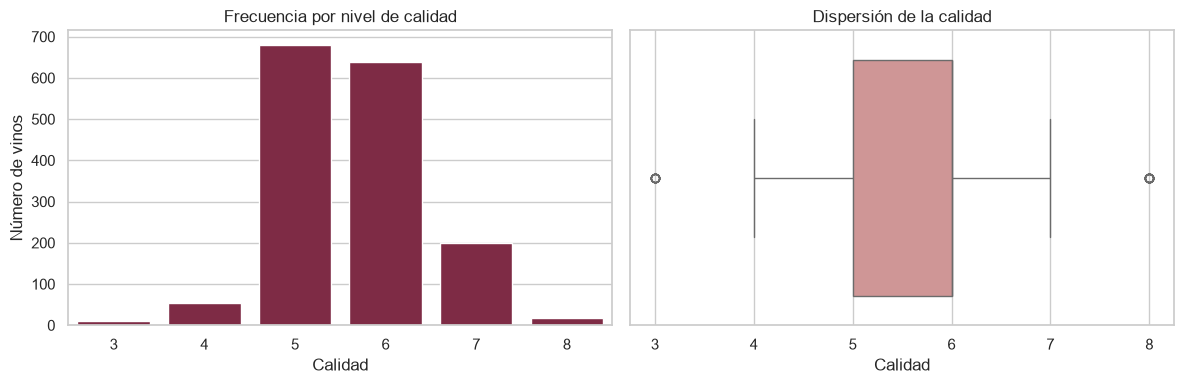

Porcentaje por nivel de calidad:


,porcentaje
quality,
3,0.63
4,3.31
5,42.59
6,39.90
7,12.45
8,1.13


In [4]:
# Distribución de la variable objetivo
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="quality", color="#8c1d40", ax=axes[0])
axes[0].set(title="Frecuencia por nivel de calidad", xlabel="Calidad", ylabel="Número de vinos")
sns.boxplot(data=df, x="quality", color="#d98c8c", ax=axes[1])
axes[1].set(title="Dispersión de la calidad", xlabel="Calidad")
plt.tight_layout()
plt.show()

quality_pct = df["quality"].value_counts(normalize=True).sort_index().mul(100).round(2)
print("Porcentaje por nivel de calidad:")
display(quality_pct.rename("porcentaje").to_frame())

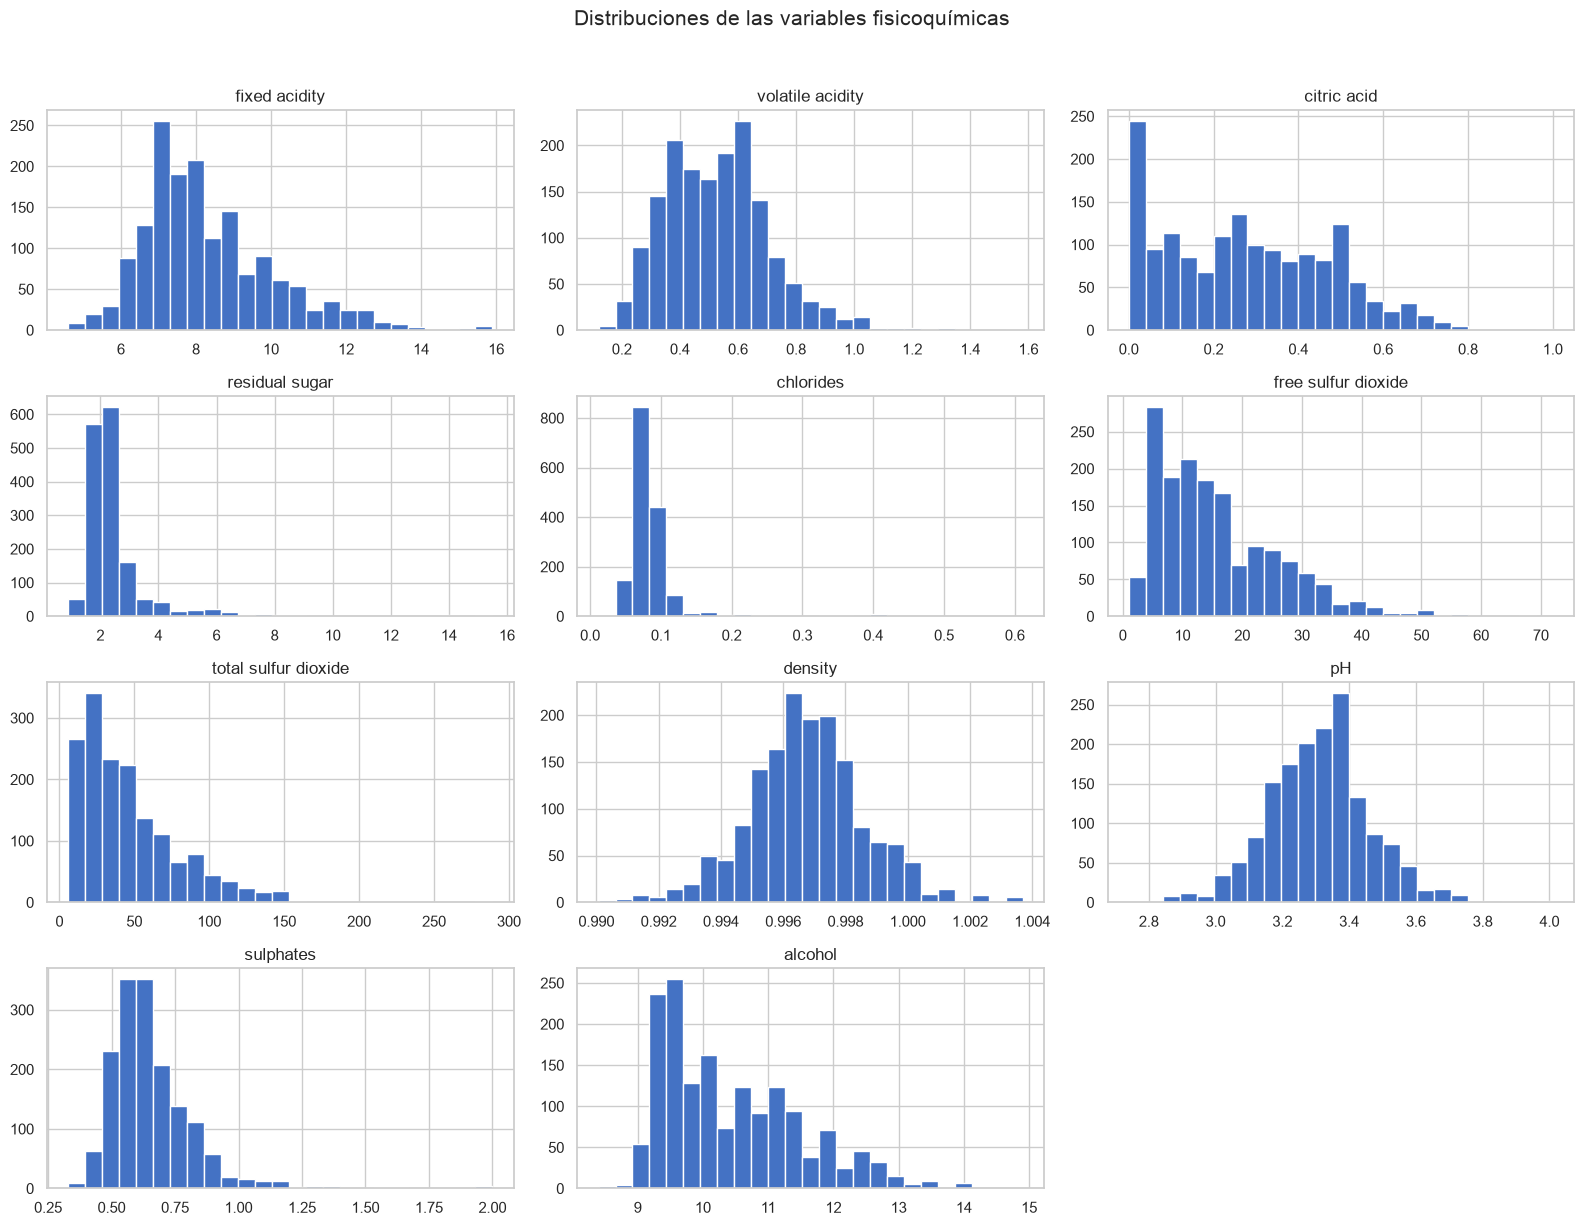

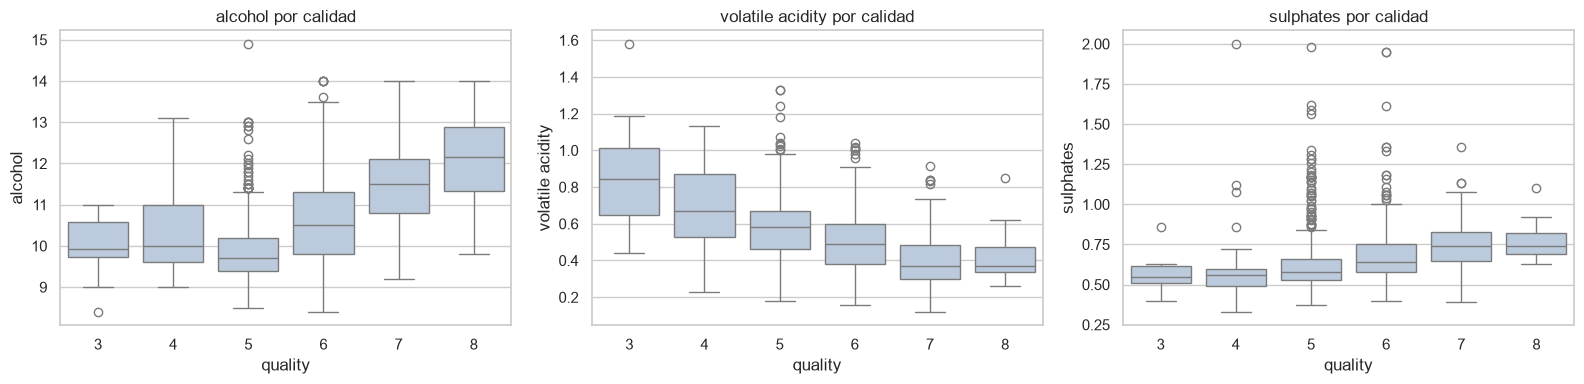

In [5]:
# Distribuciones de predictores
feature_cols = [c for c in df.columns if c != "quality"]
df[feature_cols].hist(figsize=(16, 12), bins=25, color="#4472c4", edgecolor="white")
plt.suptitle("Distribuciones de las variables fisicoquímicas", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

# Comparación de variables relevantes respecto a quality
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["alcohol", "volatile acidity", "sulphates"]):
    sns.boxplot(data=df, x="quality", y=col, color="#b7c9e2", ax=ax)
    ax.set_title(f"{col} por calidad")
plt.tight_layout()
plt.show()

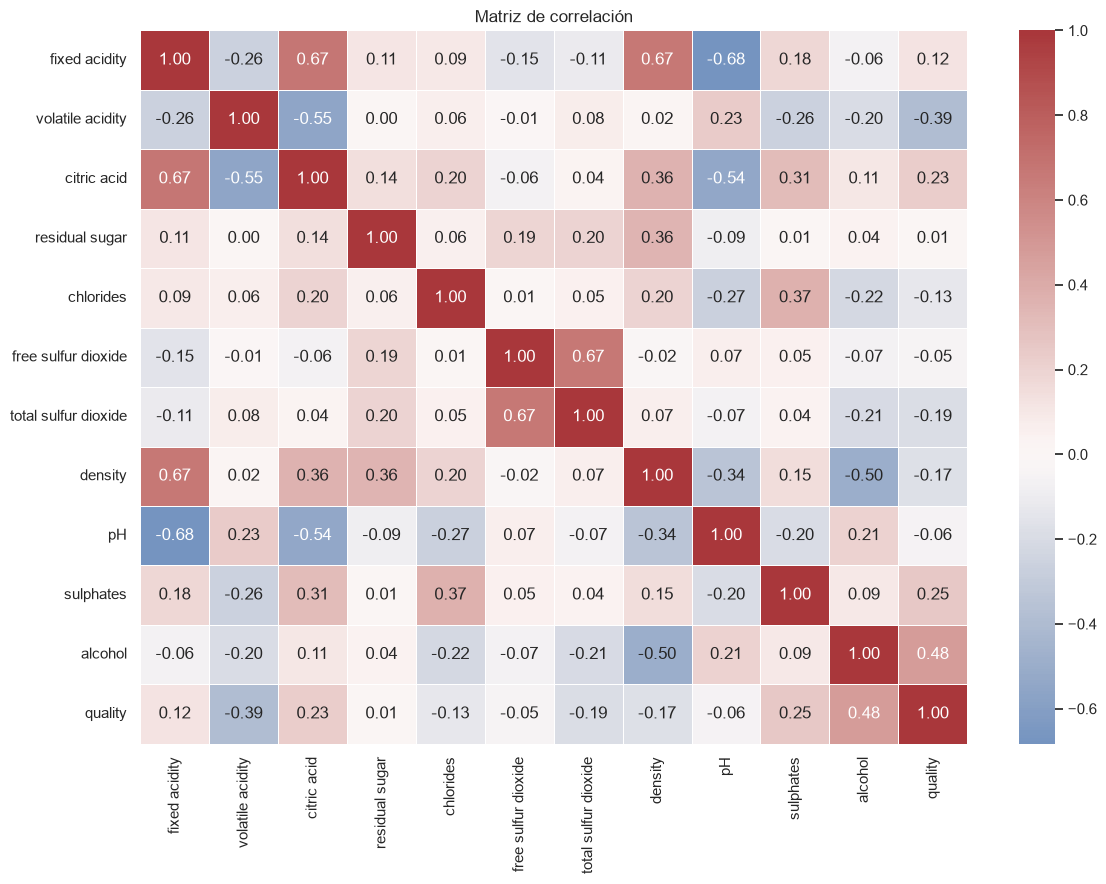

Correlación de cada predictor con quality:


,correlacion
alcohol,0.476166
volatile acidity,-0.390558
sulphates,0.251397
citric acid,0.226373
total sulfur dioxide,-0.185100
density,-0.174919
chlorides,-0.128907
fixed acidity,0.124052
pH,-0.057731
free sulfur dioxide,-0.050656


In [6]:
# Correlaciones lineales
corr = df.corr(numeric_only=True)
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", linewidths=.4)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

quality_corr = corr["quality"].drop("quality").sort_values(key=abs, ascending=False)
print("Correlación de cada predictor con quality:")
display(quality_corr.rename("correlacion").to_frame())

### Hallazgos del EDA

1. La variable `quality` está concentrada principalmente en los valores 5 y 6; las calificaciones extremas son escasas. Por ello, el modelo tendrá menos evidencia para aprender los extremos.
2. Varias variables presentan asimetría y valores alejados del centro, especialmente azúcares, cloruros y dióxido de azufre. Estos valores se investigarán, pero no se eliminarán automáticamente.
3. `alcohol`, `volatile acidity` y `sulphates` muestran asociaciones visibles con la calidad. Correlación no implica causalidad.
4. Existen correlaciones entre algunos predictores químicos. El baseline lineal puede verse afectado por multicolinealidad, aunque el objetivo de esta actividad es establecer un punto de partida interpretable, no optimizar el modelo.

## 4. Limpieza y decisiones

Se revisan faltantes, duplicados, tipos y outliers mediante IQR.

- **Faltantes:** se diagnostican y se incorpora imputación por mediana dentro del pipeline como protección reproducible. El imputador se ajustará únicamente con entrenamiento.
- **Duplicados exactos:** se eliminan antes de dividir los datos para impedir que una fila idéntica aparezca en entrenamiento y prueba. Como no existen identificadores de botella, se reconoce que algunos duplicados podrían corresponder a mediciones legítimamente iguales.
- **Tipos:** todas las columnas deben ser numéricas; `quality` se conserva como entero y se modela numéricamente.
- **Outliers:** se cuantifican con la regla 1.5×IQR, pero se conservan. No hay evidencia para afirmar que sean errores y podrían representar composiciones químicas válidas. Eliminarlos podría sesgar el rango del problema.

In [7]:
# Diagnóstico de calidad de datos
missing = df.isna().sum().rename("faltantes")
duplicates = int(df.duplicated().sum())
non_numeric = df.select_dtypes(exclude=np.number).columns.tolist()

q1 = df[feature_cols].quantile(0.25)
q3 = df[feature_cols].quantile(0.75)
iqr = q3 - q1
outlier_mask = (df[feature_cols].lt(q1 - 1.5 * iqr)) | (df[feature_cols].gt(q3 + 1.5 * iqr))
outlier_counts = outlier_mask.sum().sort_values(ascending=False).rename("outliers_IQR")

print(f"Faltantes totales: {int(missing.sum())}")
print(f"Duplicados exactos: {duplicates}")
print(f"Columnas no numéricas: {non_numeric}")
display(pd.concat([missing, outlier_counts], axis=1).fillna(0).astype(int))

# Eliminación documentada de duplicados exactos
df_clean = df.drop_duplicates().reset_index(drop=True)
assert df_clean.isna().sum().sum() == 0
assert df_clean.duplicated().sum() == 0
assert set(df_clean.columns) == set(df.columns)

print(f"Filas originales: {len(df):,}")
print(f"Filas eliminadas por duplicidad: {duplicates:,}")
print(f"Filas finales: {len(df_clean):,}")

Faltantes totales: 0
Duplicados exactos: 240
Columnas no numéricas: []


,faltantes,outliers_IQR
fixed acidity,0,49
volatile acidity,0,19
citric acid,0,1
residual sugar,0,155
chlorides,0,112
free sulfur dioxide,0,30
total sulfur dioxide,0,55
density,0,45
pH,0,35
sulphates,0,59


Filas originales: 1,599
Filas eliminadas por duplicidad: 240
Filas finales: 1,359


## 5. Preparación y modelo baseline

Se usa una separación 80/20 con semilla fija. `stratify=y` mantiene aproximadamente la distribución de los niveles de calidad, incluidos los poco frecuentes. El preprocesamiento se encapsula en un `Pipeline` para evitar fuga de información.

Se comparan dos referencias:

1. `DummyRegressor`: siempre predice la media de entrenamiento; establece el mínimo que debe superar un modelo útil.
2. `LinearRegression`: baseline interpretable para cuantificar una relación lineal entre las mediciones y la calidad.

No se realiza ajuste de hiperparámetros porque la consigna solicita un baseline.

In [8]:
X = df_clean.drop(columns="quality")
y = df_clean["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

baseline_model = Pipeline([
    ("preprocessing", preprocessing),
    ("regressor", LinearRegression()),
])

dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train, y_train)
baseline_model.fit(X_train, y_train)

print(f"Entrenamiento: {len(X_train):,} filas")
print(f"Prueba: {len(X_test):,} filas")
print("Distribución de quality en prueba:")
display(y_test.value_counts(normalize=True).sort_index().rename("proporción").to_frame())

Entrenamiento: 1,087 filas
Prueba: 272 filas
Distribución de quality en prueba:


,proporción
quality,
3,0.007353
4,0.040441
5,0.426471
6,0.393382
7,0.121324
8,0.011029


,mae,rmse,r2
Dummy (media),0.6921,0.8191,-0.0002
Regresión lineal,0.5066,0.6523,0.3657


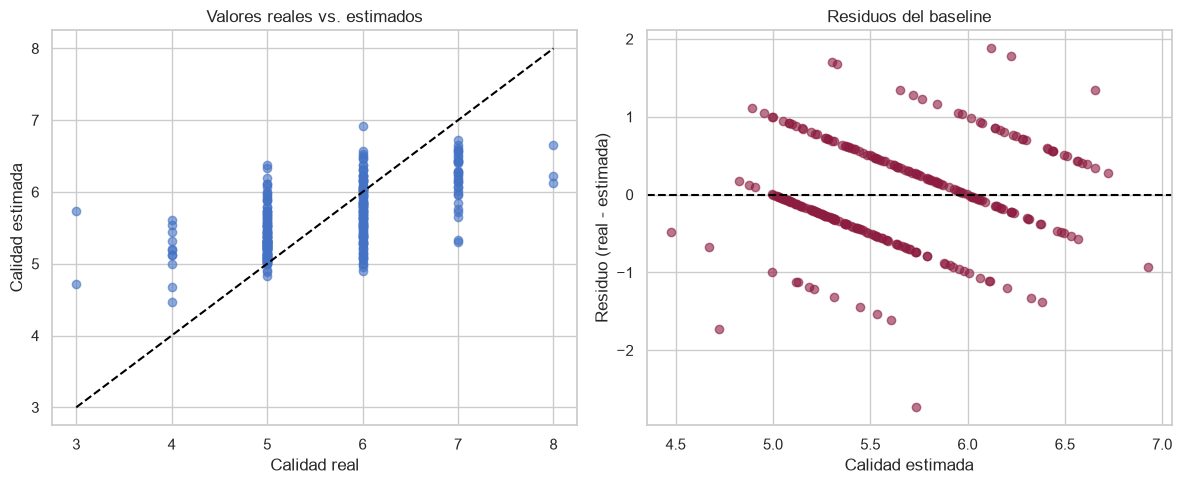

### Interpretación de la evaluación

- El **MAE es 0.507 puntos de calidad**. En promedio, la predicción se separa esa cantidad de la calificación observada.
- El **RMSE es 0.652**. Al penalizar con mayor intensidad los errores grandes, permite detectar si algunas observaciones son especialmente difíciles.
- El **R² es 0.366**: el modelo explica aproximadamente el 36.6% de la variabilidad de `quality` en prueba.
- Frente al predictor ingenuo de la media, el MAE mejora aproximadamente **26.8%**.

El modelo ofrece un punto de partida mejor que predecir siempre la media, pero su capacidad explicativa es limitada. La concentración de calificaciones en 5 y 6 favorece predicciones cercanas al centro y dificulta acertar los extremos. Además, una regresión lineal no representa interacciones ni relaciones no lineales. Las métricas describen asociación predictiva, no causalidad química.

In [9]:
def regression_metrics(y_true, y_pred):
    """Calcula métricas coherentes con un problema de regresión."""
    return {
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": mean_squared_error(y_true, y_pred) ** 0.5,
        "r2": r2_score(y_true, y_pred),
    }

pred_dummy = dummy_model.predict(X_test)
pred_baseline = baseline_model.predict(X_test)

dummy_metrics = regression_metrics(y_test, pred_dummy)
baseline_metrics = regression_metrics(y_test, pred_baseline)
metrics_table = pd.DataFrame(
    [dummy_metrics, baseline_metrics],
    index=["Dummy (media)", "Regresión lineal"],
)
display(metrics_table.round(4))

# Diagnóstico visual de predicciones y residuos
residuals = y_test.to_numpy() - pred_baseline
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, pred_baseline, alpha=0.6, color="#4472c4")
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "--", color="black")
axes[0].set(xlabel="Calidad real", ylabel="Calidad estimada", title="Valores reales vs. estimados")
axes[1].scatter(pred_baseline, residuals, alpha=0.6, color="#8c1d40")
axes[1].axhline(0, linestyle="--", color="black")
axes[1].set(xlabel="Calidad estimada", ylabel="Residuo (real - estimada)", title="Residuos del baseline")
plt.tight_layout()
residual_plot_path = ARTIFACT_DIR / "baseline_residuals.png"
plt.savefig(residual_plot_path, dpi=160, bbox_inches="tight")
plt.show()

improvement = 100 * (dummy_metrics["mae"] - baseline_metrics["mae"]) / dummy_metrics["mae"]
display(Markdown(
    f"""### Interpretación de la evaluación

- El **MAE es {baseline_metrics['mae']:.3f} puntos de calidad**. En promedio, la predicción se separa esa cantidad de la calificación observada.
- El **RMSE es {baseline_metrics['rmse']:.3f}**. Al penalizar con mayor intensidad los errores grandes, permite detectar si algunas observaciones son especialmente difíciles.
- El **R² es {baseline_metrics['r2']:.3f}**: el modelo explica aproximadamente el {baseline_metrics['r2']*100:.1f}% de la variabilidad de `quality` en prueba.
- Frente al predictor ingenuo de la media, el MAE mejora aproximadamente **{improvement:.1f}%**.

El modelo ofrece un punto de partida mejor que predecir siempre la media, pero su capacidad explicativa es limitada. La concentración de calificaciones en 5 y 6 favorece predicciones cercanas al centro y dificulta acertar los extremos. Además, una regresión lineal no representa interacciones ni relaciones no lineales. Las métricas describen asociación predictiva, no causalidad química."""
))

## 6. Registro del experimento en MLflow

Se registran parámetros de reproducibilidad, métricas de prueba, el modelo, una muestra del dataset y las visualizaciones principales. El tracking se almacena localmente en la base SQLite `mlflow.db`, backend recomendado por versiones recientes de MLflow.

Para abrir la interfaz después de ejecutar el notebook:

```bash
.venv/bin/mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```

Después se abre `http://127.0.0.1:5000` y se selecciona el experimento `TC5061_Wine_Quality_Baseline`.

In [10]:
# Configuración local de MLflow con backend SQLite
tracking_db = (PROJECT_ROOT / "mlflow.db").resolve()
mlflow.set_tracking_uri(f"sqlite:///{tracking_db}")
mlflow.set_experiment("TC5061_Wine_Quality_Baseline")

# Artefactos auxiliares reproducibles
clean_sample_path = ARTIFACT_DIR / "clean_data_sample.csv"
df_clean.head(100).to_csv(clean_sample_path, index=False)

run_name = "linear_regression_red_wine"
with mlflow.start_run(run_name=run_name) as run:
    mlflow.log_params({
        "dataset": "UCI Wine Quality - red wine",
        "model": "LinearRegression",
        "random_state": RANDOM_STATE,
        "test_size": TEST_SIZE,
        "imputer": "median",
        "scaler": "StandardScaler",
        "original_rows": len(df),
        "clean_rows": len(df_clean),
        "duplicates_removed": duplicates,
        "n_features": X.shape[1],
    })
    mlflow.log_metrics({
        "test_mae": baseline_metrics["mae"],
        "test_rmse": baseline_metrics["rmse"],
        "test_r2": baseline_metrics["r2"],
        "dummy_mae": dummy_metrics["mae"],
        "dummy_rmse": dummy_metrics["rmse"],
        "dummy_r2": dummy_metrics["r2"],
    })
    mlflow.set_tags({
        "course": "TC5061",
        "task": "baseline",
        "problem_type": "regression",
        "data_source": "UCI Machine Learning Repository",
    })
    mlflow.log_artifact(str(clean_sample_path), artifact_path="data")
    mlflow.log_artifact(str(residual_plot_path), artifact_path="plots")
    mlflow.log_artifact(str(ARTIFACT_DIR / "correlation_heatmap.png"), artifact_path="plots")
    mlflow.sklearn.log_model(
        baseline_model,
        name="linear_regression_pipeline",
        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE,
    )
    run_id = run.info.run_id

print(f"Experimento registrado correctamente. Run ID: {run_id}")
print(f"Tracking URI: {mlflow.get_tracking_uri()}")

2026/10/04 17:13:45 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Experimento registrado correctamente. Run ID: 854e0c277dcd47d9a13ece2d75d964fb
Tracking URI: sqlite:////Users/carlos/Documents/09_Proy_Neni/Arquitectura/NeniBot/mlflow.db


## 7. Evidencia de MLflow

La siguiente celda muestra la captura de la interfaz de MLflow si el archivo está disponible. La captura debe permitir leer el nombre del experimento, el run, sus parámetros y sus métricas.

**Ruta esperada:** `artifacts/mlflow_experiment.png`

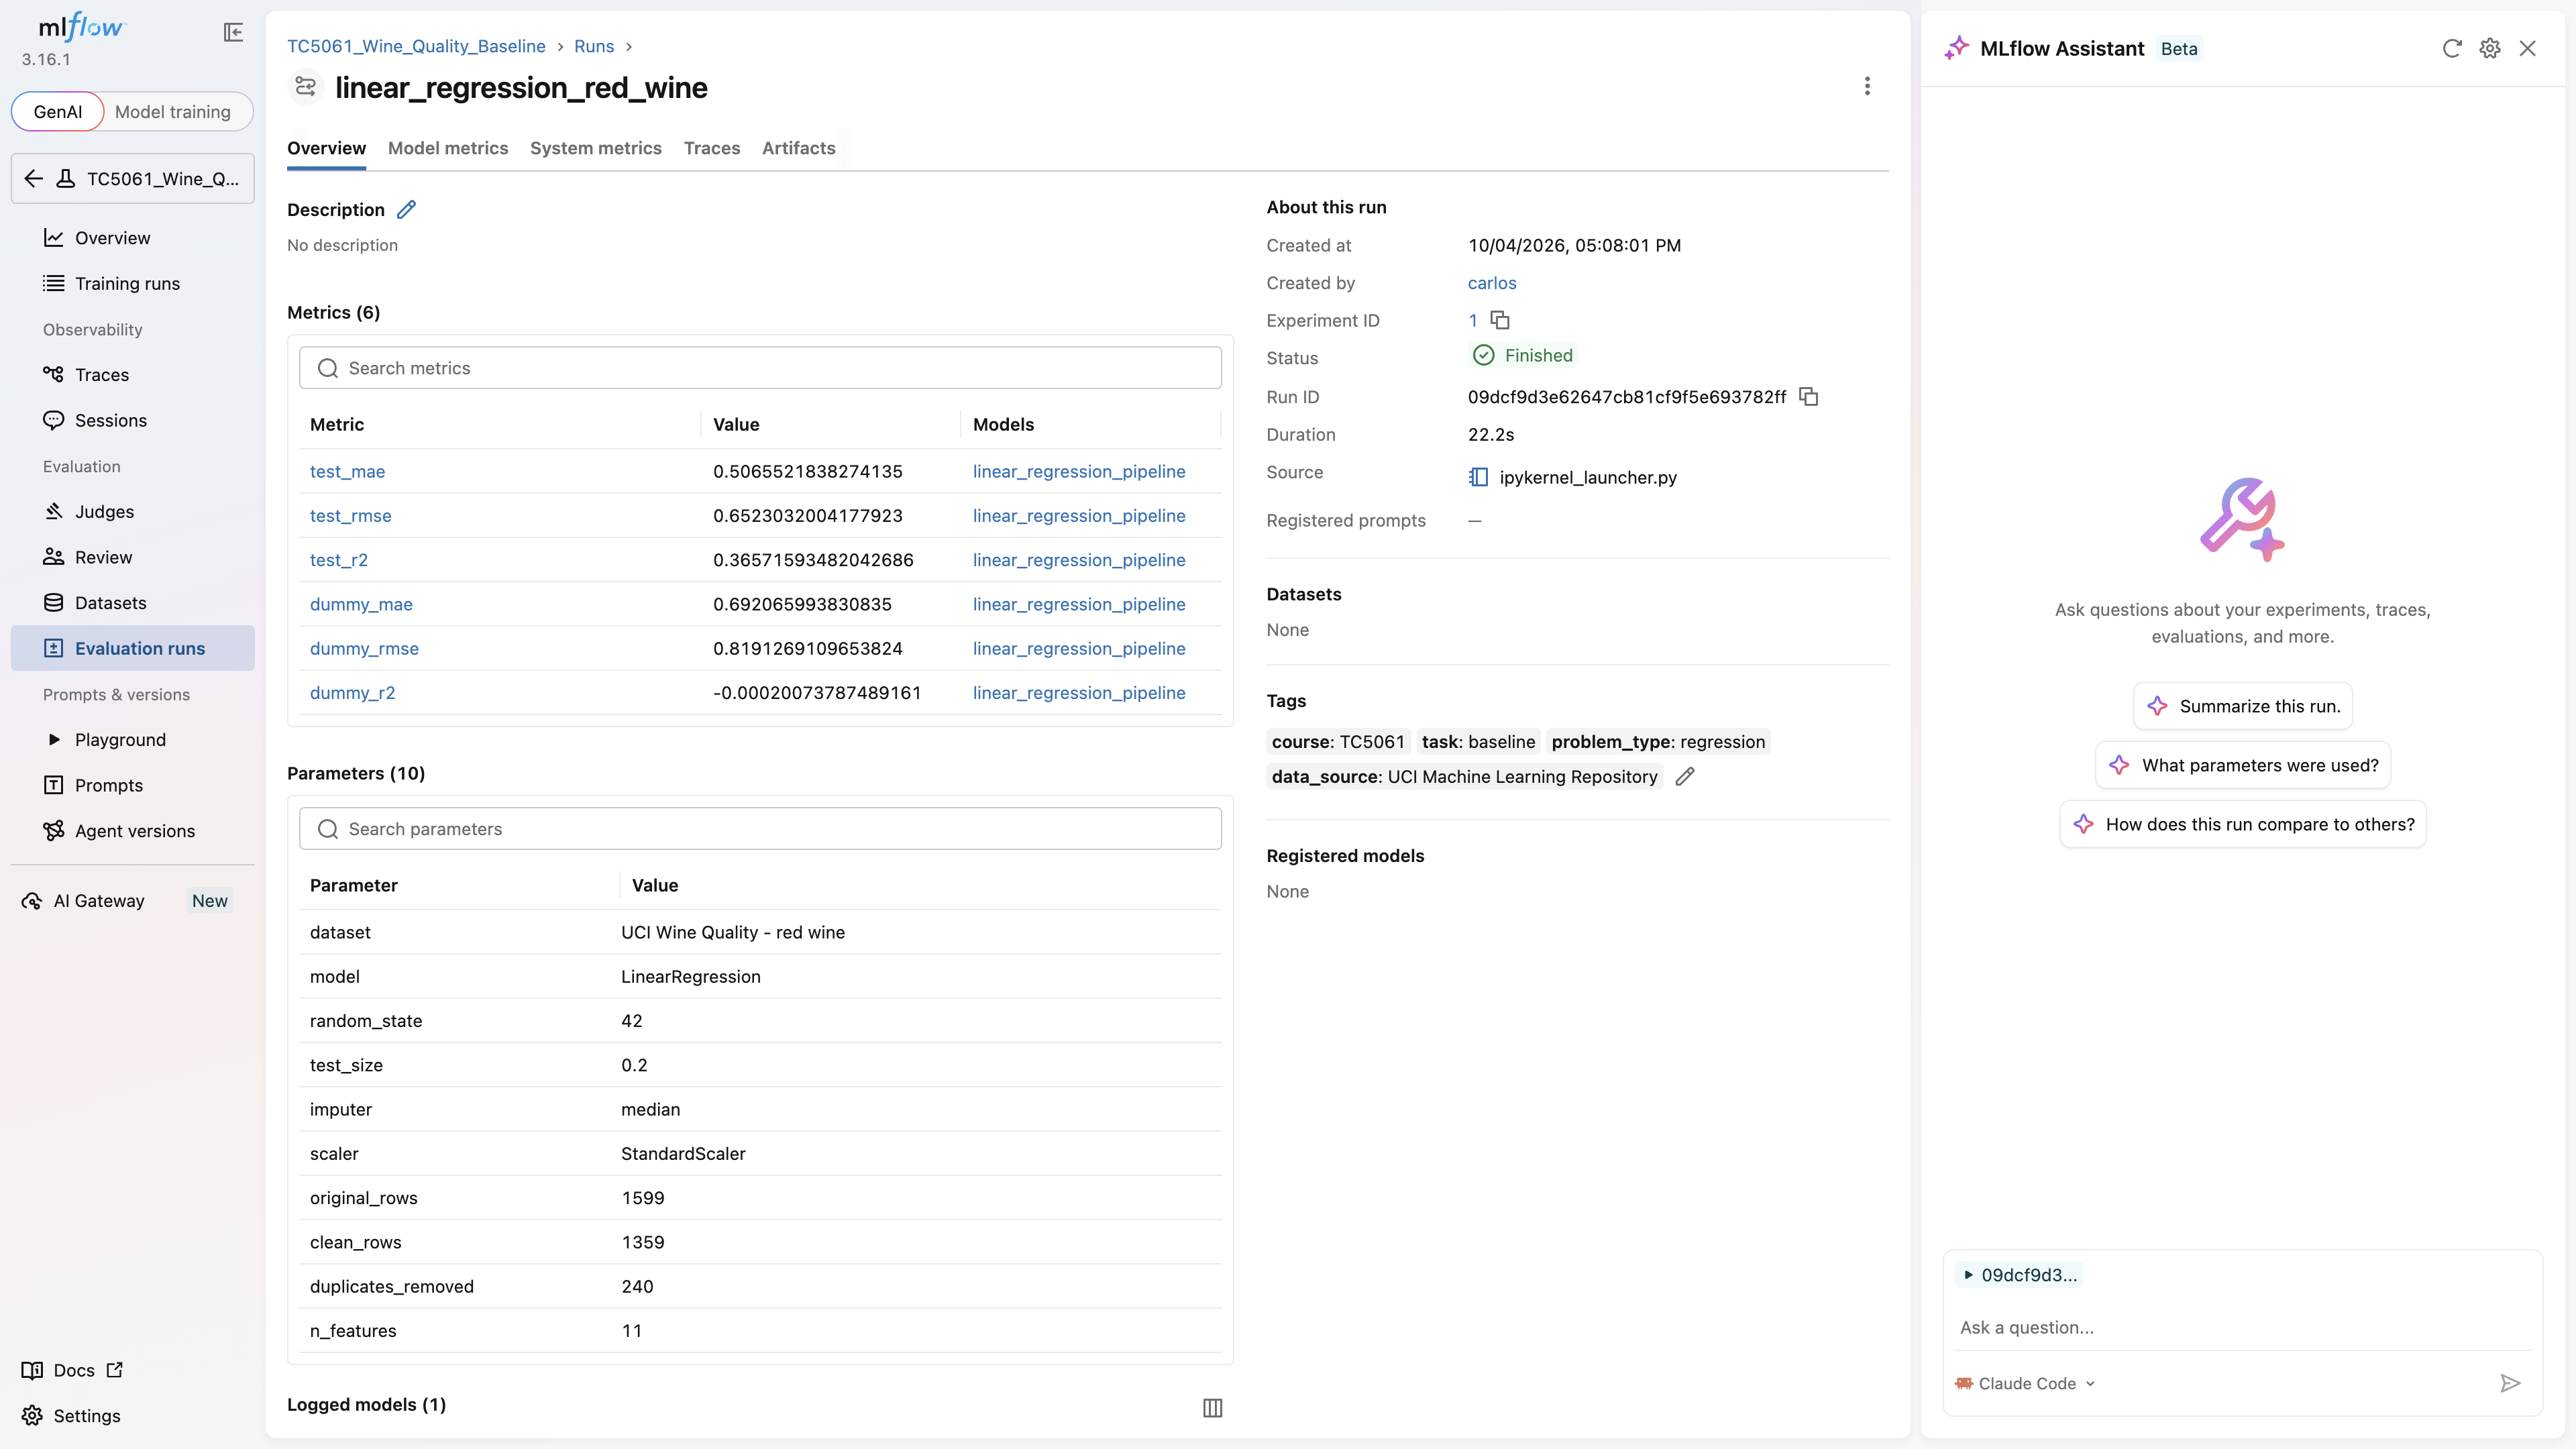

In [11]:
mlflow_screenshot = ARTIFACT_DIR / "mlflow_experiment.png"
if mlflow_screenshot.exists():
    display(Image(filename=str(mlflow_screenshot)))
else:
    display(Markdown(
        "⚠️ **Captura pendiente:** inicia `mlflow ui`, abre el run registrado, "
        "guarda la captura como `artifacts/mlflow_experiment.png` y vuelve a ejecutar esta celda."
    ))

## 8. Reflexión final

Este ejercicio muestra que construir un modelo no consiste únicamente en llamar a un algoritmo. Primero fue necesario comprender el origen y significado de los datos, revisar sus distribuciones y documentar decisiones que pueden modificar el resultado, como eliminar duplicados exactos y conservar valores extremos potencialmente válidos. También aprendí que la evaluación debe considerar un punto de comparación: obtener métricas sin compararlas con un predictor ingenuo puede dar una impresión equivocada sobre la utilidad del modelo. La regresión lineal es interpretable y reproducible, pero explica solo una parte de la variación de la calidad. Esto es razonable porque una evaluación sensorial también depende de factores que no están presentes, como el catador, el proceso de producción, el almacenamiento y posibles interacciones no lineales entre compuestos.

Aplicando mejores prácticas de MLOps, mejoraría el flujo con validación cruzada, pruebas automáticas de esquema y rangos, versionado del dataset y comparación controlada de modelos como Ridge, Random Forest y Gradient Boosting. También registraría cada transformación, el código y las dependencias exactas, promovería modelos mediante un registro y vigilaría cambios en la distribución de los datos y en el error después de desplegar. MLflow aporta trazabilidad porque conserva parámetros, métricas y artefactos de cada ejecución, lo que permite reproducir y comparar resultados sin depender de notas manuales.

En mi área profesional, estos aprendizajes se reflejan en la necesidad de construir soluciones auditables y mantenibles. Un resultado predictivo solo genera confianza cuando puede explicarse de dónde salieron los datos, qué limpieza se aplicó, con qué versión se entrenó y bajo qué métricas se decidió utilizarlo. Por ello, el valor de MLOps está en convertir un experimento aislado en un proceso verificable, colaborativo y susceptible de mejora continua.

## 9. Conclusiones y reproducibilidad

- La regresión lineal funciona como baseline interpretable y debe compararse con el predictor de la media.
- Las propiedades fisicoquímicas contienen señal predictiva, pero no explican por completo una valoración sensorial.
- El desbalance hacia calidades 5 y 6 limita el aprendizaje en los extremos.
- El experimento quedó registrado en MLflow con parámetros, métricas, modelo y gráficas.

Para reproducir la entrega desde la raíz del proyecto:

```bash
.venv/bin/jupyter nbconvert --to notebook --execute \
  TC5061_Notebook_Baseline_CarlosOjeda.ipynb \
  --output TC5061_Notebook_Baseline_CarlosOjeda.ipynb \
  --ExecutePreprocessor.timeout=600
```
> Esta actividad fue elaborada con ayuda de Cursor: se usó para guiar la actividad y revisar que cumpla con lo esperado. Modelo usado: GPT-5.6 Sol de OpenAI.

### Referencias

- UCI Machine Learning Repository. (2009). *Wine Quality* [Dataset]. https://archive.ics.uci.edu/dataset/186/wine+quality
- Cortez, P., Cerdeira, A., Almeida, F., Matos, T. y Reis, J. (2009). *Modeling wine preferences by data mining from physicochemical properties*. Decision Support Systems, 47(4), 547–553.